# Лабораторная работа №2

## Задания

![Задания](./tasks.png "Задания")

## Библиотеки

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from statsmodels.tsa.seasonal import seasonal_decompose, STL, MSTL
from statsmodels.graphics.tsaplots import plot_acf

## Реализация

### Загрузка данных

In [2]:
df = pd.read_csv("series.csv", parse_dates=["timestamp"])
df.head()

,timestamp,value
0,2026-11-19 00:00:00,73.034622
1,2026-11-19 01:00:00,106.134064
2,2026-11-19 02:00:00,85.315327
3,2026-11-19 03:00:00,102.612039
4,2026-11-19 04:00:00,98.318745


### Необходимые преобразования

In [3]:
def adjust_df(df_orig):
    # Сортировка и проверка дубликатов
    df = df_orig.sort_values("timestamp").drop_duplicates("timestamp").set_index("timestamp")

    # Установка временного индекса и проверка частоты
    full_idx = pd.date_range(df.index.min(), df.index.max(), freq="h")
    df = df.reindex(full_idx)
    df.index.name = "timestamp"

    return df

In [4]:
df = adjust_df(df)
df.head()

,value
timestamp,
2026-11-19 00:00:00,73.034622
2026-11-19 01:00:00,106.134064
2026-11-19 02:00:00,85.315327
2026-11-19 03:00:00,102.612039
2026-11-19 04:00:00,98.318745


### График ряда

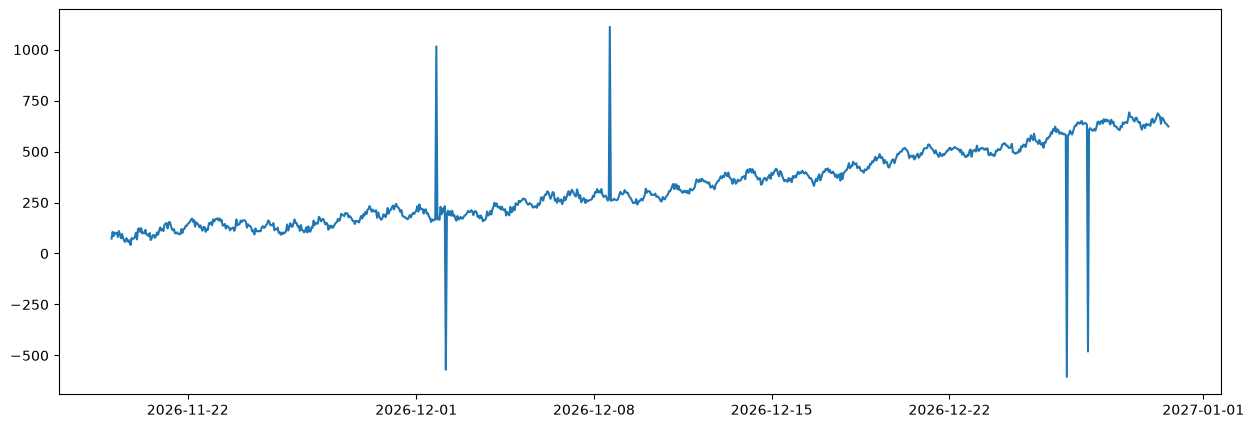

In [5]:
plt.figure(figsize=(15, 5))
plt.plot(df.index, df["value"], label="y")
plt.show()

Здесь прослеживается **аддитивная модель**, так как:
1. Ряд имеет отрицательные значения
2. Амплитуда сезонности примерно постоянна
3. Нет экспоненциального роста

### Суточные и недельные подсерии

In [6]:
def plot_seasonal_subseries(df_orig):
    df = df_orig.copy()
    df["day_of_week"] = df.index.day_of_week
    df["hour"] = df.index.hour
    
    fig, axes = plt.subplots(7, 1, figsize=(15, 20))
    
    for day, ax in enumerate(axes):
        subset = df[df["day_of_week"] == day]  # 0 - понедельник, 1 - вторник и т.д.
    
        sns.lineplot(data=subset, x='hour', y='value', ax=ax, errorbar=None)
    
        ax.set_title(['Пн', 'Вт', 'Ср', 'Чт', 'Пт', 'Сб', 'Вс'][day])  # чтобы было понятнее
    
        ax.set_xticks(range(24))
    
    plt.tight_layout()
    plt.show()

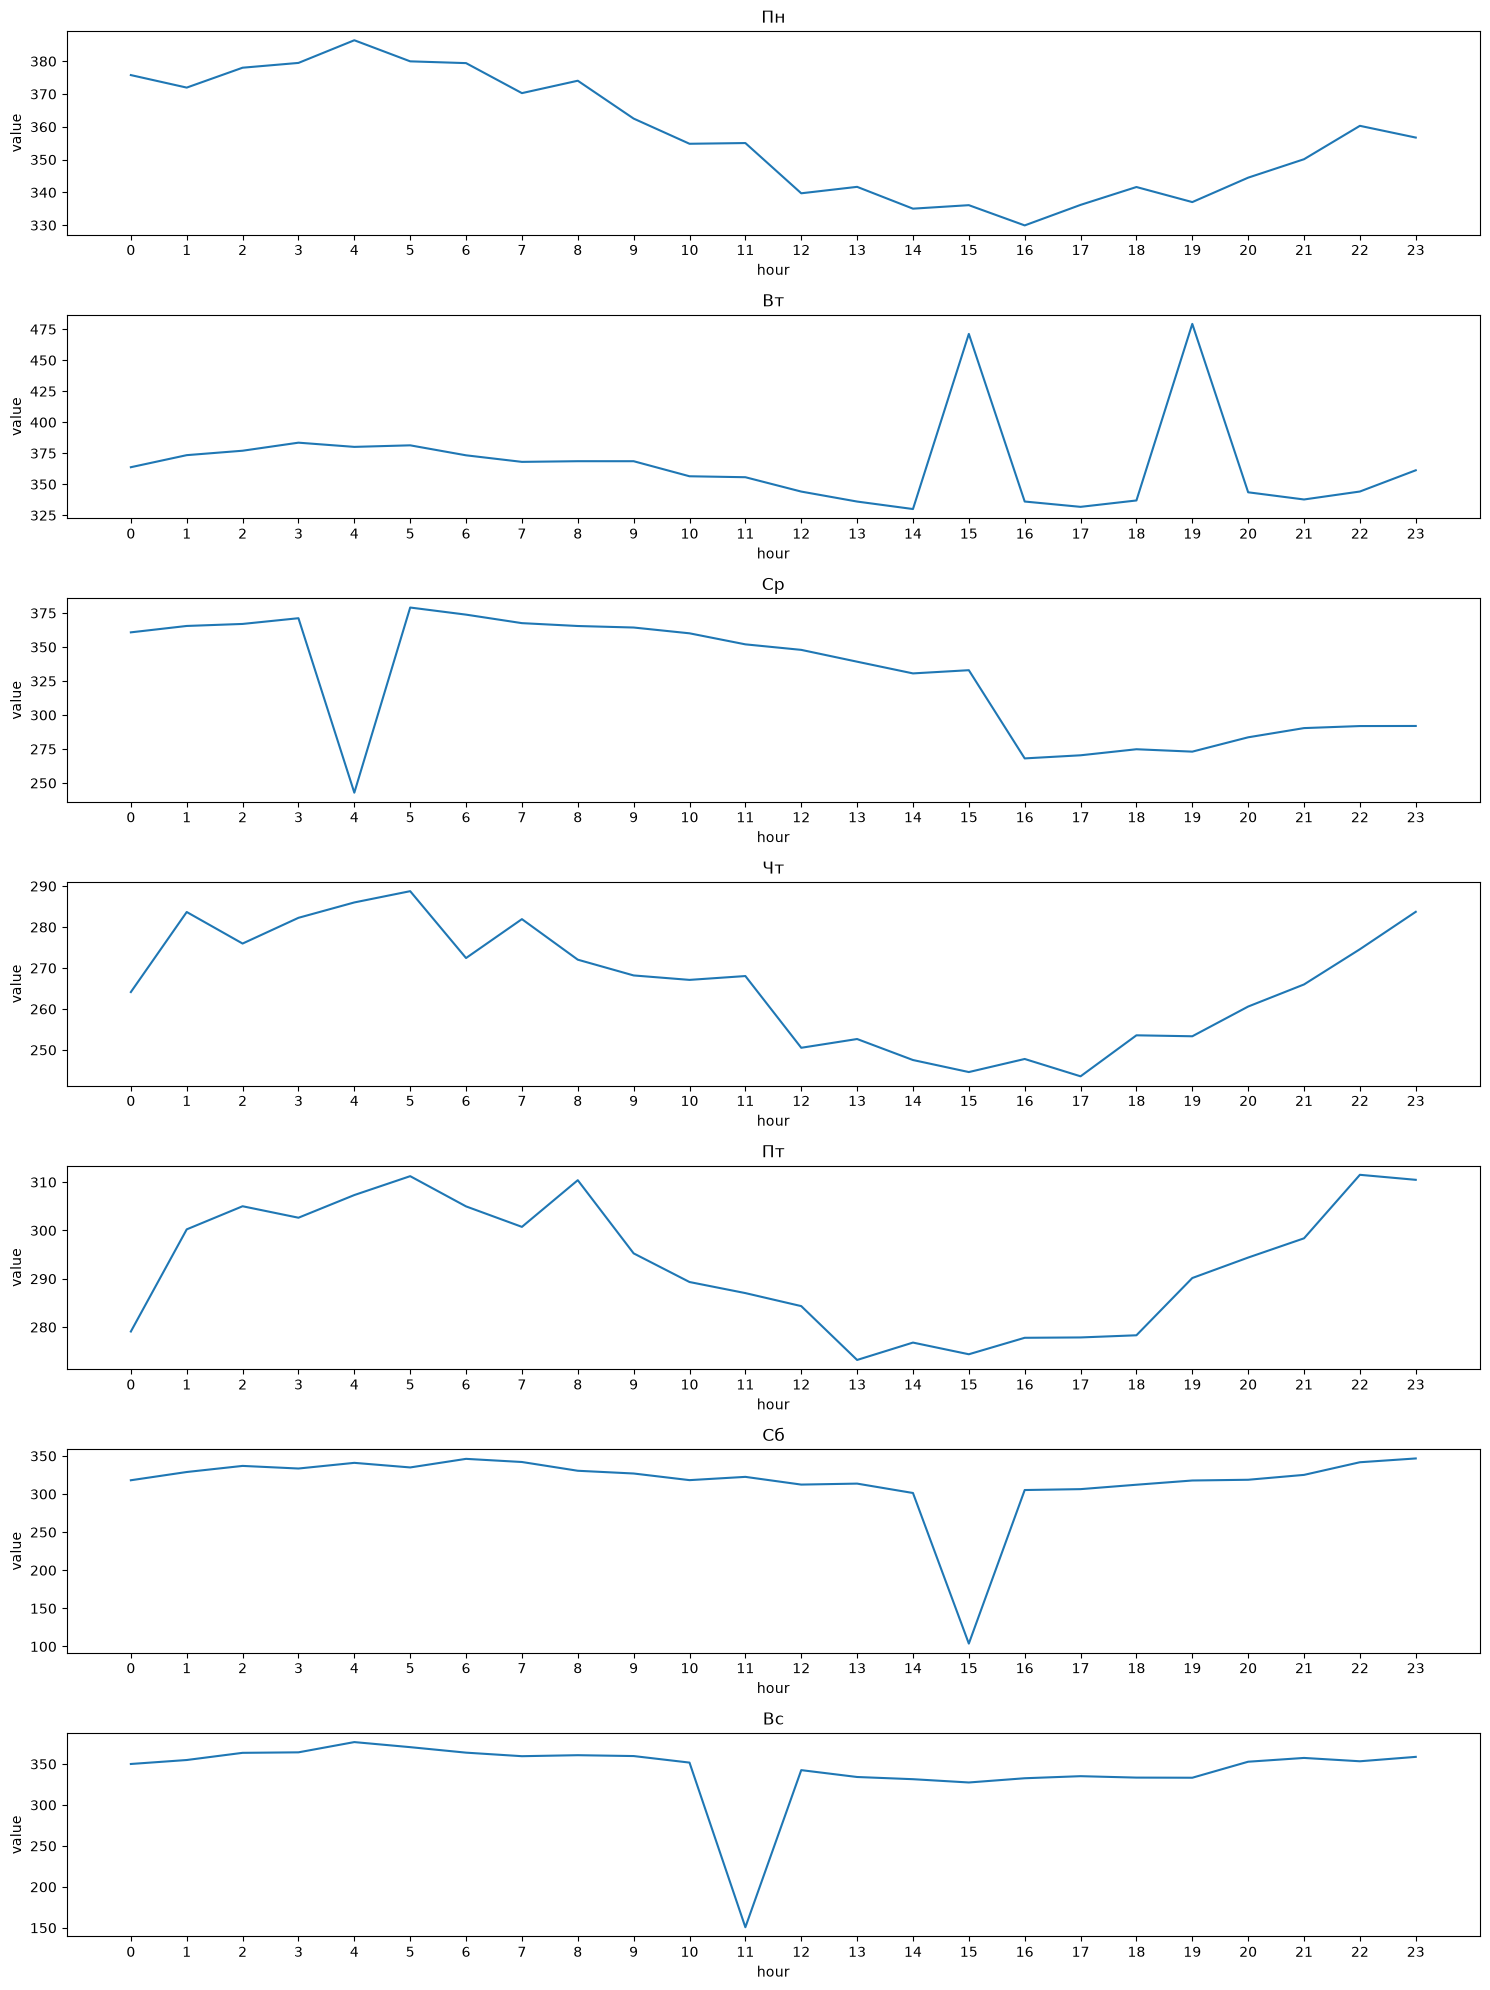

In [7]:
plot_seasonal_subseries(df)

### Тепловая карта "час x день недели"

In [8]:
def plot_heatmap(df_orig):
    df = df_orig.copy()
    df["day_of_week"] = df.index.day_of_week
    df["hour"] = df.index.hour
    
    heatmap_data = df.pivot_table(index='hour', columns='day_of_week', values='value', aggfunc='mean')

    plt.figure(figsize=(10, 10))

    sns.heatmap(heatmap_data, cmap='viridis', annot=False, linewidths=0.5)
    
    plt.xlabel('День недели')
    plt.ylabel('Час')
    
    plt.xticks(ticks=np.arange(7) + 0.5, labels=['Пн', 'Вт', 'Ср', 'Чт', 'Пт', 'Сб', 'Вс'])
    
    plt.show()

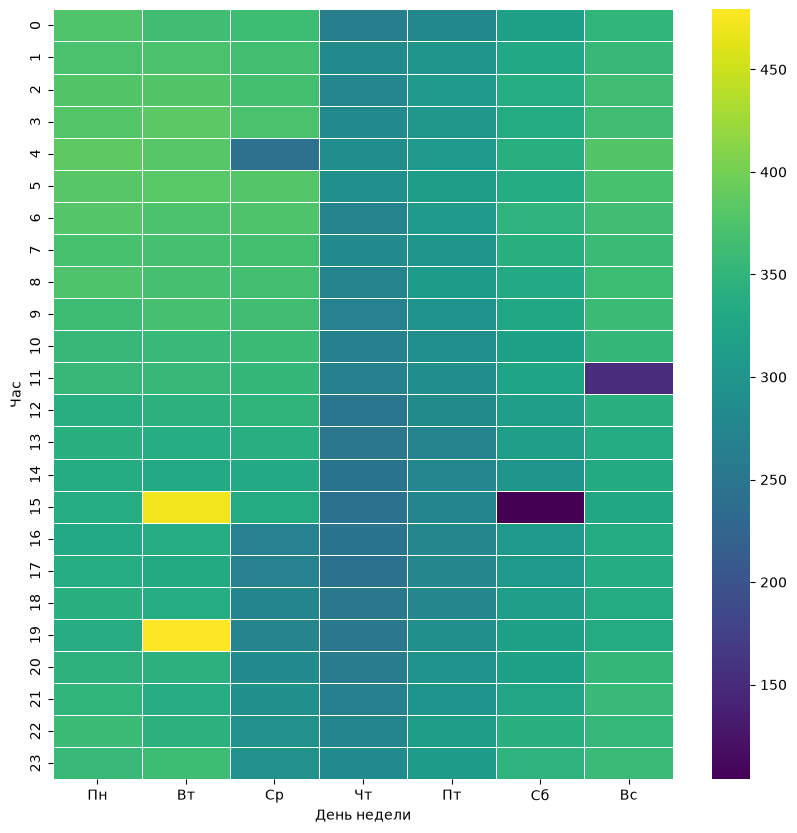

In [9]:
plot_heatmap(df)

### Автокоррелирующая функция

In [10]:
def better_plot_acf(df):
    fig, ax = plt.subplots(figsize=(20, 5))
    plot_acf(df, ax=ax, lags=168, zero=False, missing="drop")
    ax.set_xticks(np.arange(0, 192, 24))
    ax.grid()
    plt.show()

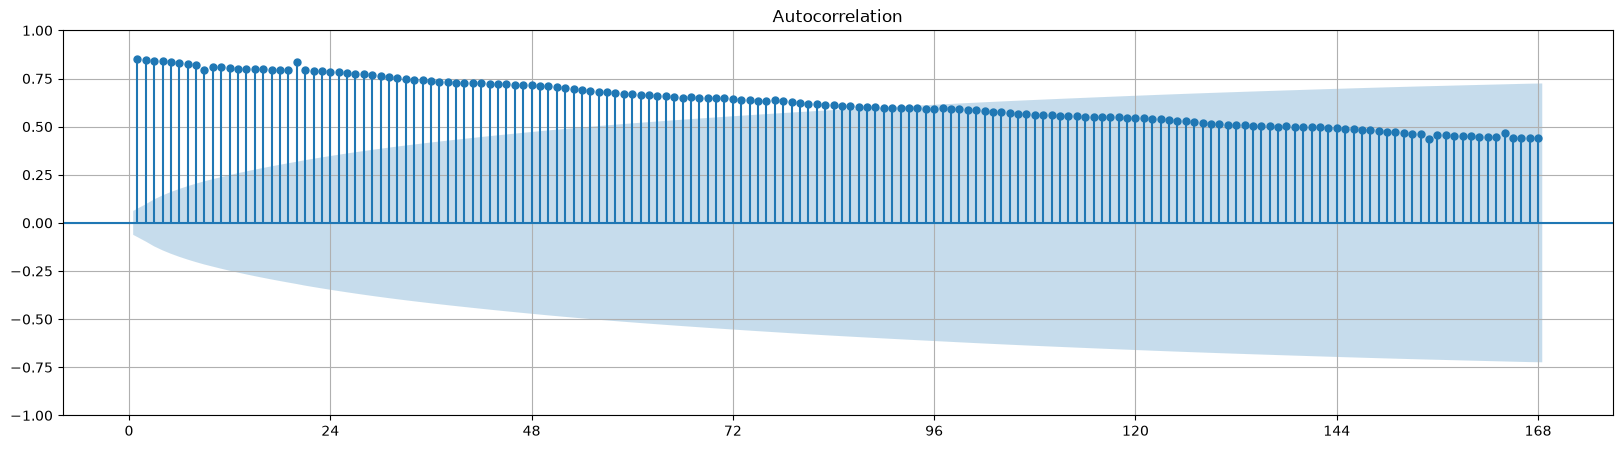

In [11]:
better_plot_acf(df)

Видно пики у лагов 24 и 168

### Декомпозиция

In [12]:
def plot_decomp(decomposed):
    fig, axes = plt.subplots(3, 1, figsize=(12, 15))

    trend = decomposed.trend
    axes[0].plot(trend.index, trend)
    axes[0].set_title("Тренд")
    axes[0].grid()

    seasonal = decomposed.seasonal
    axes[1].plot(seasonal.index, seasonal)
    axes[1].set_title("Сезонность")
    axes[1].grid()

    resid = decomposed.resid
    axes[2].plot(resid.index, resid)
    axes[2].set_title("Остаток")
    axes[2].grid()
    
    plt.tight_layout()
    plt.show()

#### Классическая декомпозиция

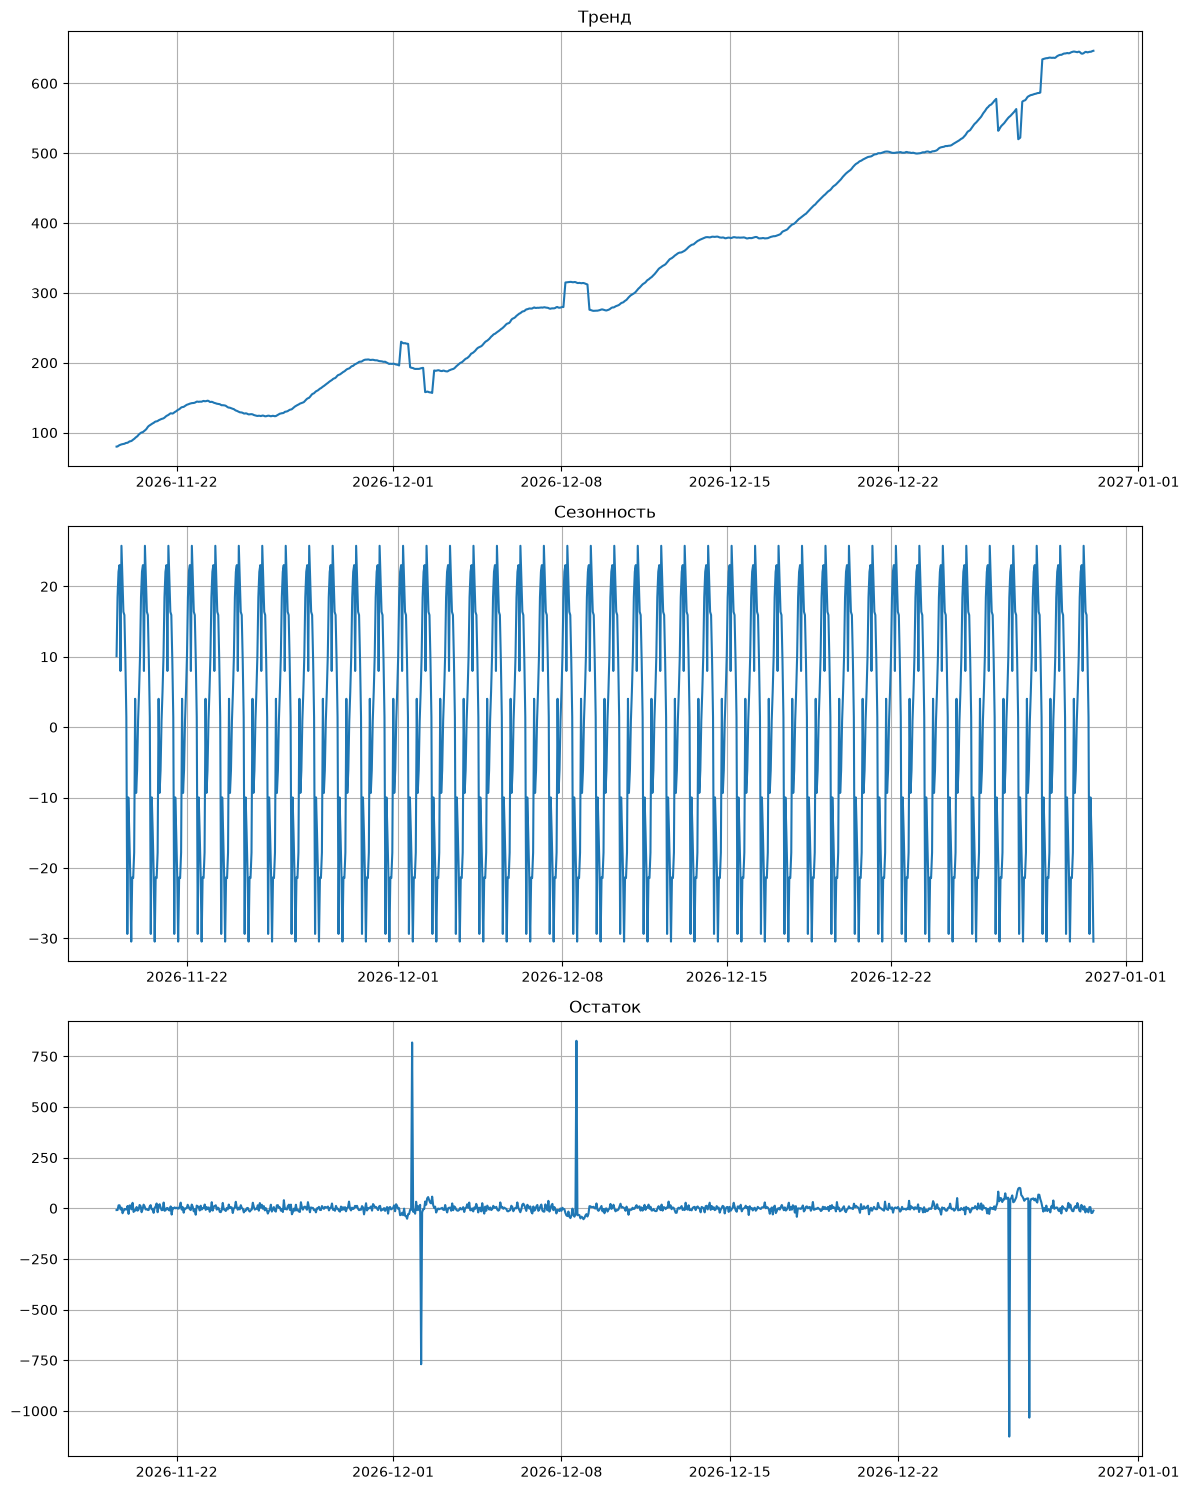

In [13]:
classic_decomp = seasonal_decompose(df, period=24)
plot_decomp(classic_decomp)

Слегка видна недельная структура в остатке

#### STL декомпозиция

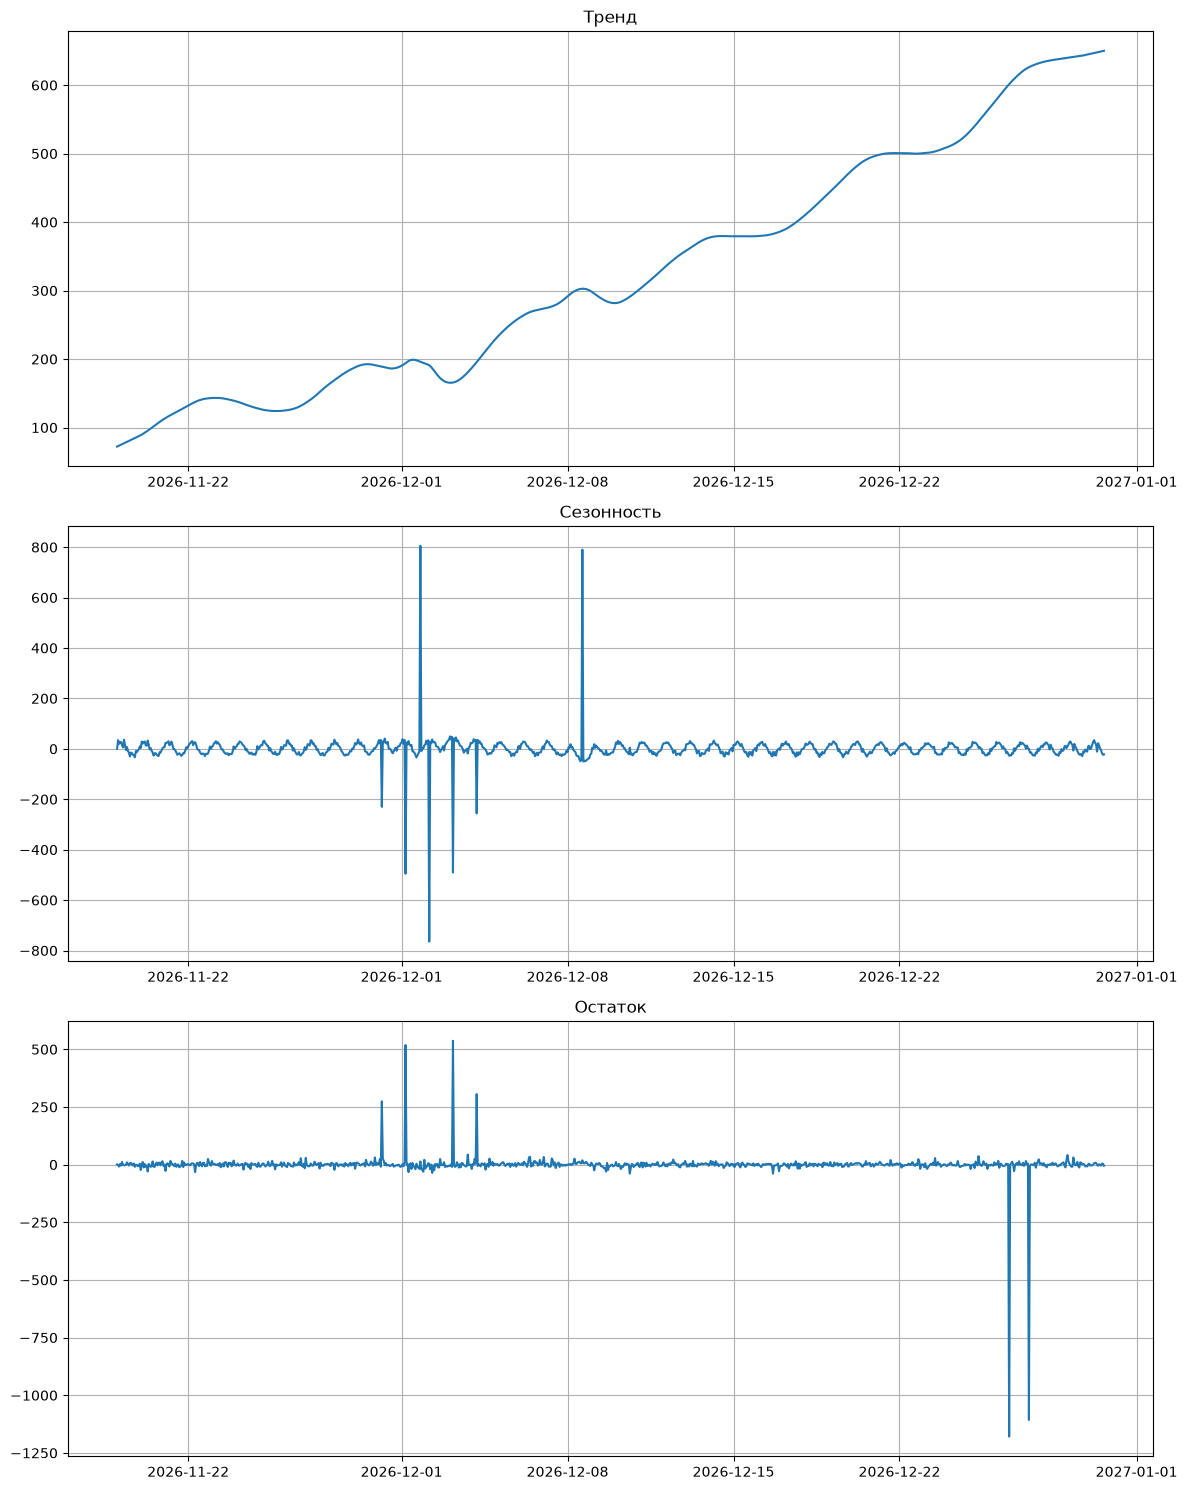

In [14]:
stl_decomp = STL(df, period=24, robust=True).fit()
plot_decomp(stl_decomp)

Дневная структура стала выделяться лучше, но недельной всё ещё нет

#### MSTL декомпозиция

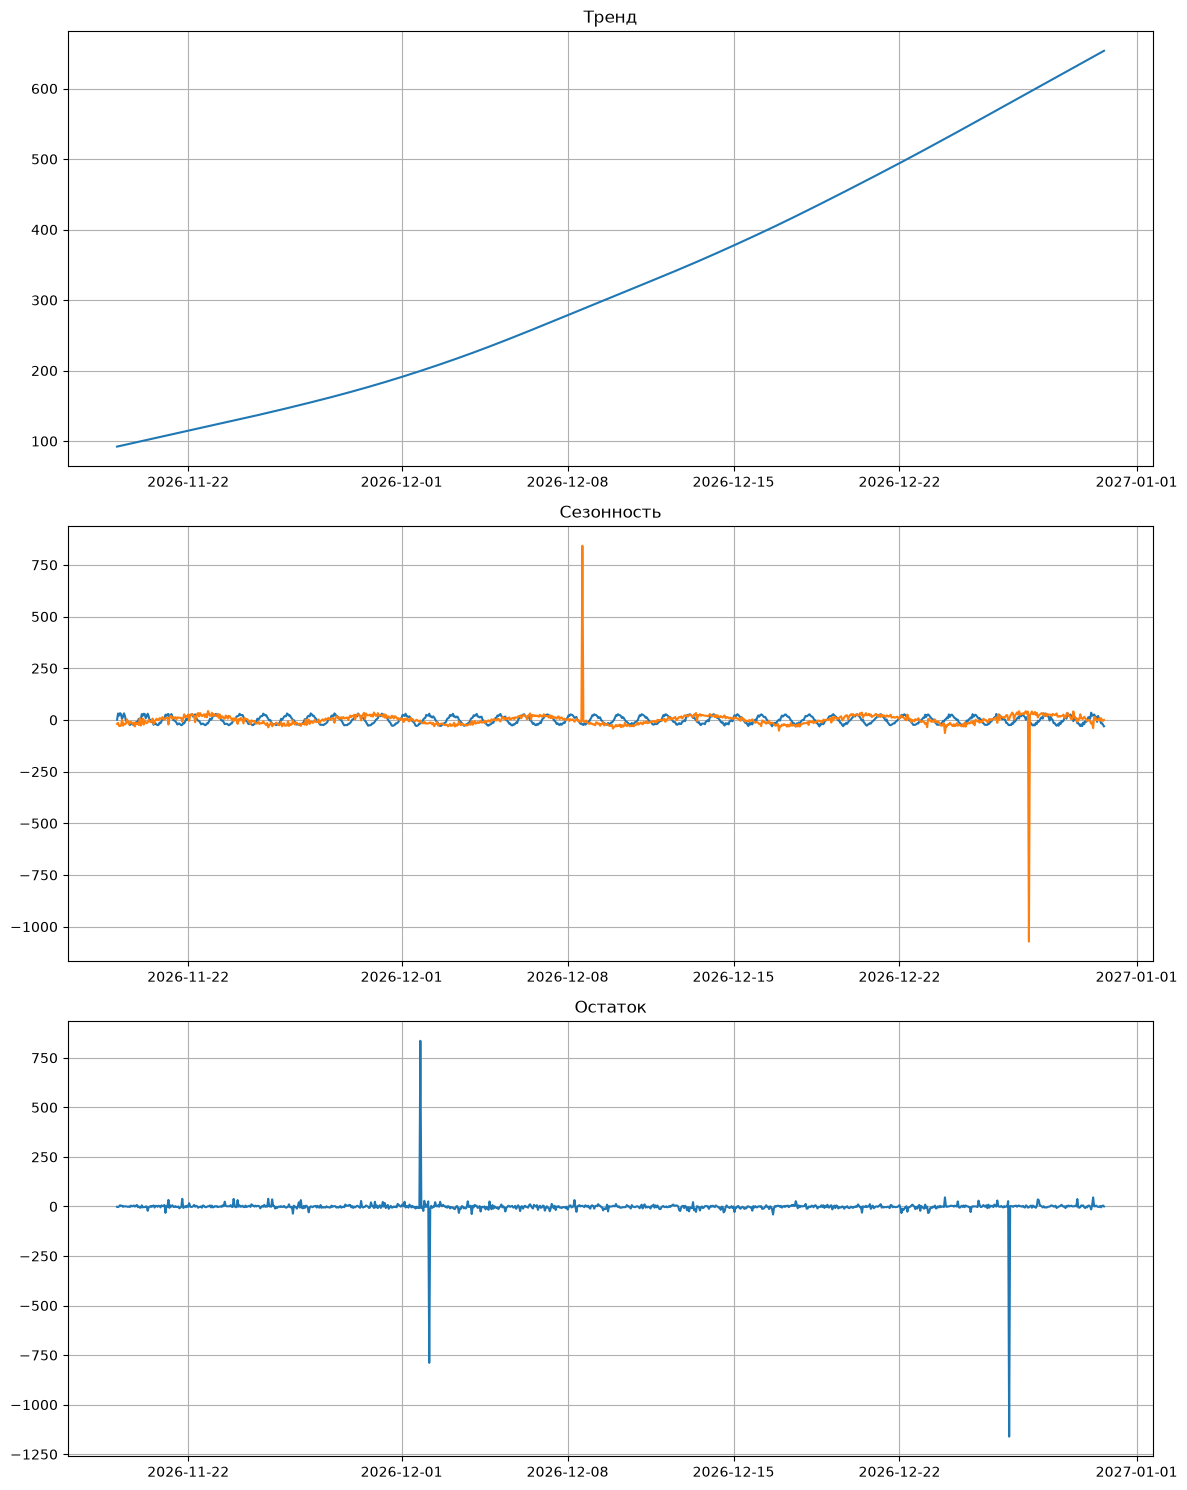

In [15]:
mstl_decomp = MSTL(df, periods=(24, 168), stl_kwargs={"robust": True}).fit()
plot_decomp(mstl_decomp)

Видны обе сезонности (помечены разными цветами), остаток стал чище, чёткий тренд

### Количественные сравнения

#### Дисперсии остатка

In [16]:
print("Классическая декомпозиция:", classic_decomp.resid.var())
print("STL декомпозиция:", stl_decomp.resid.var())
print("MSTL декомпозиция:", mstl_decomp.resid.var())

Классическая декомпозиция: 4723.0174296088535
STL декомпозиция: 3424.82588305764
MSTL декомпозиция: 2749.1572800626036


#### Автокорреляция остатка классической декомпозиции

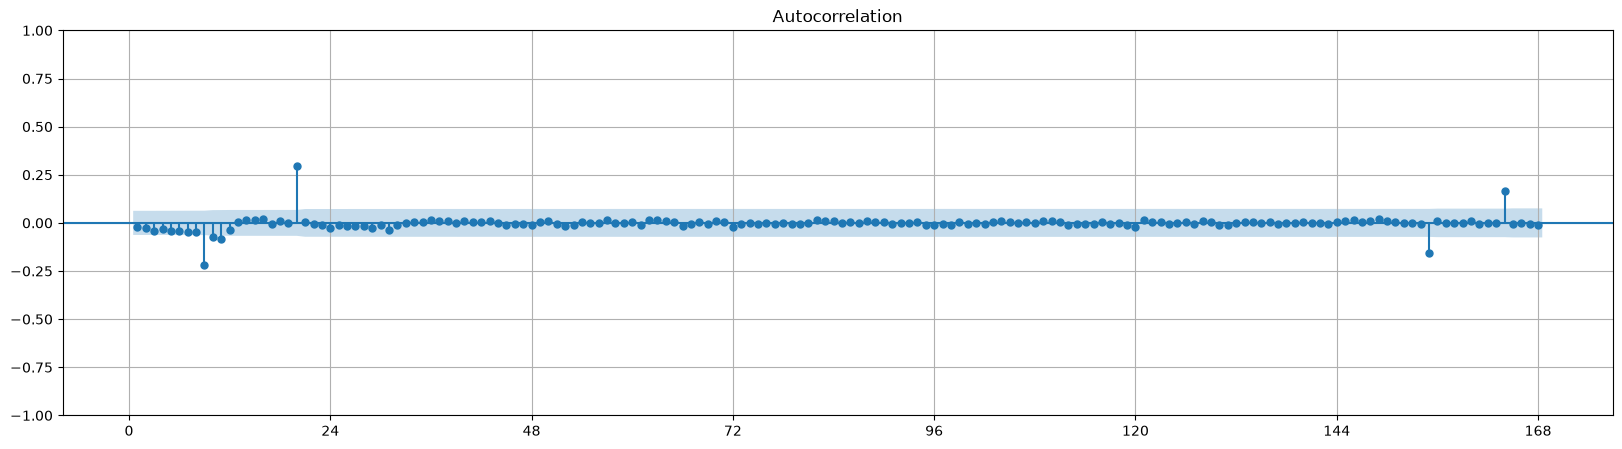

In [17]:
better_plot_acf(classic_decomp.resid)

#### Автокорреляция остатка STL декомпозиции

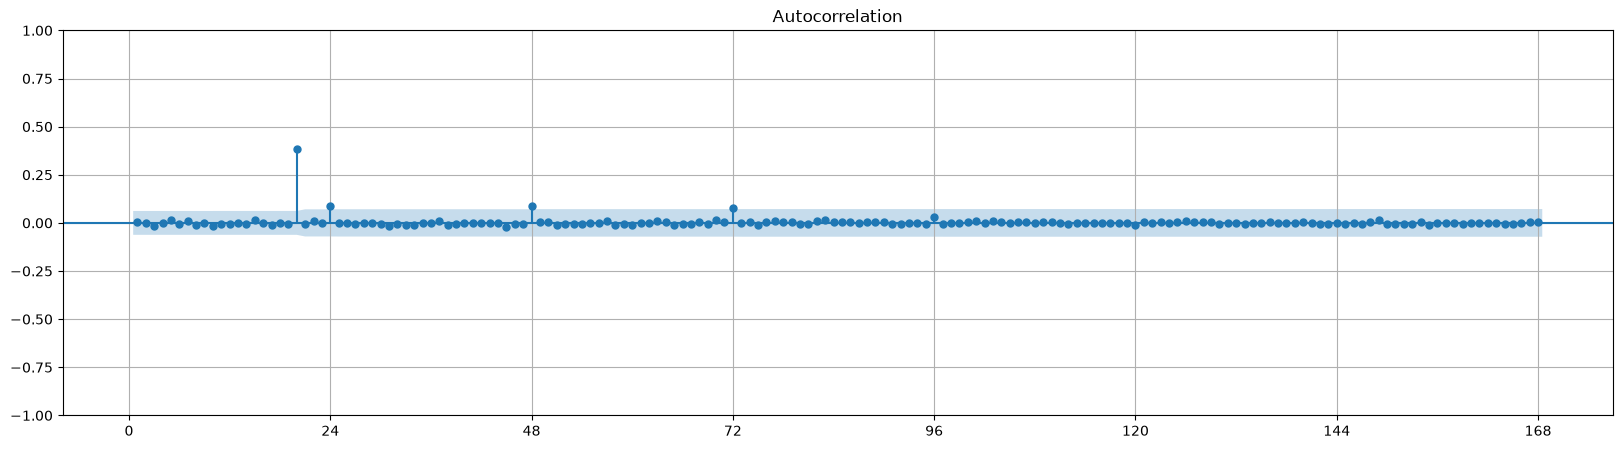

In [18]:
better_plot_acf(stl_decomp.resid)

#### Автокорреляция остатка MSTL декомпозиции

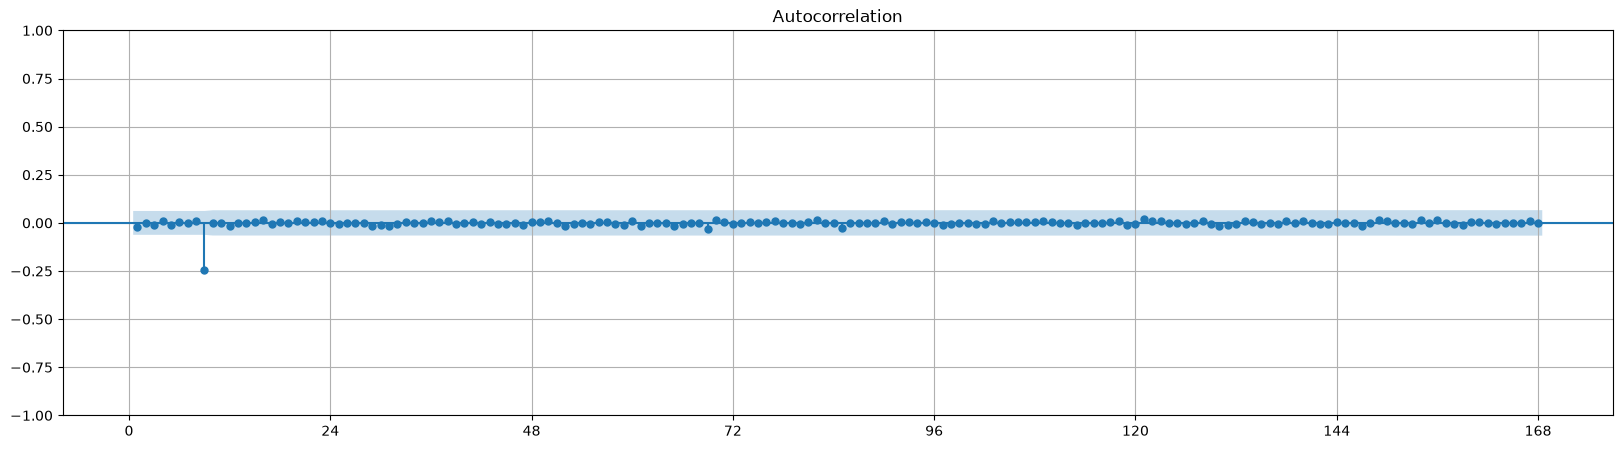

In [19]:
better_plot_acf(mstl_decomp.resid)

Видно, что у классической и STL декомпозиций есть автокорреляция в остатке, в то время как у MSTL её почти что нет (только одно значение, но это скорее погрешность)

Также стоит отметить, что у MSTL заметно чище компоненты, чем у STL и особенно у классической

Тренд похож на параболу (особенно хорошо это видно у MSTL), что соответствует правде (т.к. тренд сгенерированного ряда им и задавался)

Для простых задач с одной постоянной сезонной компонентой и без выбросов подходит классическая декомпозиция

Для задач с одной меняющейся сезонной компонентой и с выбросами подходит STL

Для задач с несколькими меняющимися сезонными компонентами и с выбросами подходит MSTL

### Подбор параметров STL

Я решил взять сезонное сглаживание за 167 (т.к. вторая сезонность равна 7 дней; 7 дней = 168 часов) и такое же значение тренда (чтобы уловить тренд за неделю). Брать большие значения я считаю смысла нет, т.к. сезонность уже покрыта, а тренд не экспоненциальный

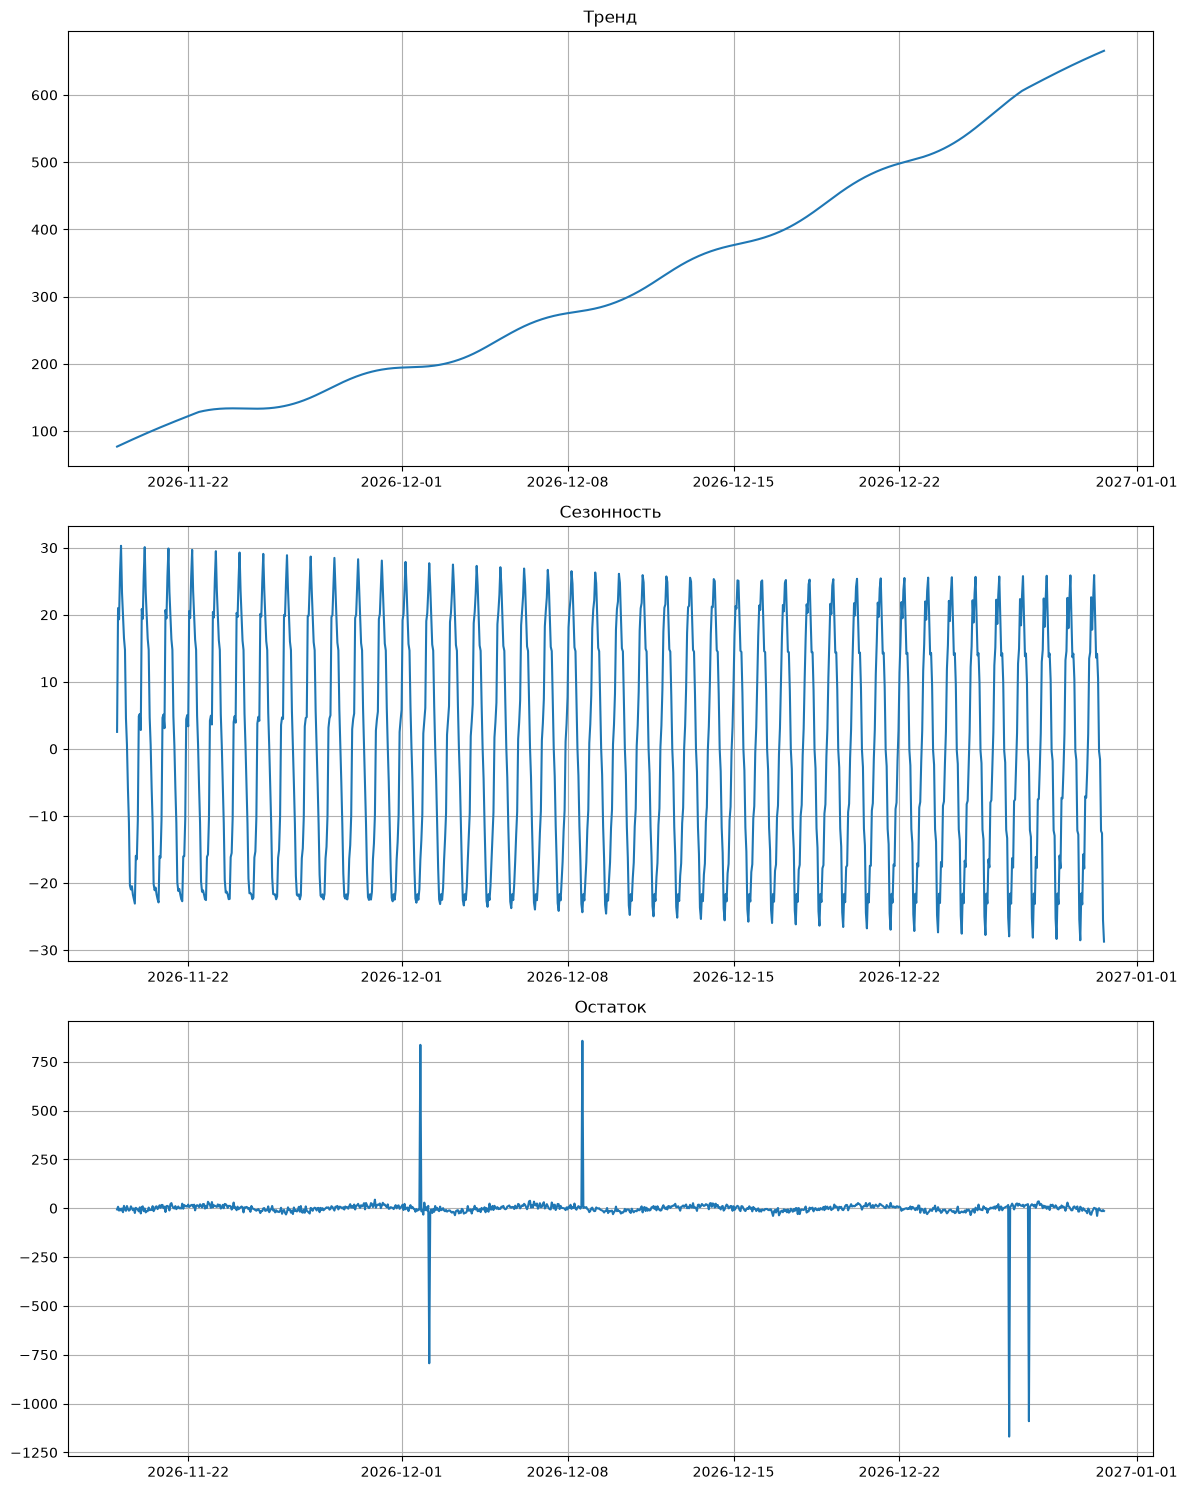

In [20]:
stl_decomp = STL(df, period=24, robust=True, seasonal=167, trend=167).fit()
plot_decomp(stl_decomp)

### Выводы

Для данного ряда лучше всего подходит MSTL, так как:
1. Имеется две сезонности
2. Модель ряда аддитивная
3. Есть несколько выбросов
4. Ряд имеет часовую структуру